# 1-03 실적발표 이벤트 스터디 — 발표 전후 주가 반응과 서프라이즈

**질문 예시:** "삼성전자 실적발표날 주가 어떻게 움직였어?", "실적 나오기 전에 이미 올랐던 거야?"

CHECK 원본(`1_기업펀더멘털/03_실적발표이벤트스터디`)은 발표일·주가·**외국인/기관 수급**을 함께 봤습니다.
DeepSearch에는 투자자별 수급이 없어서 그 부분은 빼고, 대신 다음을 넣었습니다.

| 항목 | DeepSearch |
|---|---|
| 발표일 | 거래소 공시 `영업(잠정)실적(공정공시)`의 접수 시각 (`DocumentSearch`, 공시) |
| 주가 반응 | `GetStockPrices` + 코스피 지수(`GetMarketIndexes`)로 **시장 대비 초과수익** |
| 거래량 반응 | 발표일 거래량 ÷ 직전 20거래일 평균 |
| 서프라이즈 | 분기 실제 영업이익(`GetFinancialStatements`) vs 발표 직전 90일 증권사 추정 평균(`SearchFirmFundamentalsForecasts`) |
| 외국인·기관 수급 | **없음** (DeepSearch 미제공, `research/data_gaps`) |

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/1_fundamentals/03_earnings_event_study.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"            # 기준일
STOCK = "KRX:005930"           # 종목 (삼성전자)
NAME = "삼성전자"
LOOKBACK_START = "2025-11-25"  # 발표일을 찾을 기간 시작 (공시 검색은 1년 이내)
WINDOW = 10                    # 발표 전후 거래일 수
print(PRICE_NOTICE)

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


## 1. 실적 발표일 찾기
삼성전자는 분기마다 **잠정실적(분기 첫 주)**과 **확정 실적 설명(분기 말)** 두 번 `영업(잠정)실적` 공시를 냅니다.
`[기재정정]`은 빼고, 장 마감(15:30) 뒤 공시는 다음 거래일을 반응 첫날(D0)로 잡습니다.

In [4]:
total, ann = doc_search("company", ["disclosure"], f"securities.name:{NAME} and title:잠정",
                        LOOKBACK_START, ASOF, count=50)
ann = ann[ann["title"].str.contains("영업\\(잠정\\)실적") & ~ann["title"].str.contains("정정")]
ann = ann[ann["publisher"] == NAME].sort_values("created_at").reset_index(drop=True)
ann["구분"] = ann.groupby(ann["created_at"].dt.to_period("Q")).cumcount().map({0: "잠정(1차)", 1: "확정 설명(2차)"})
ann[["created_at", "구분", "title"]]

,created_at,구분,title
0,2026-01-08 07:42:37,잠정(1차),연결재무제표기준영업(잠정)실적(공정공시)
1,2026-01-29 07:39:09,확정 설명(2차),연결재무제표기준영업(잠정)실적(공정공시)
2,2026-04-07 07:43:30,잠정(1차),연결재무제표기준영업(잠정)실적(공정공시)
3,2026-04-30 08:47:20,확정 설명(2차),연결재무제표기준영업(잠정)실적(공정공시)
4,2026-07-07 07:41:05,잠정(1차),연결재무제표기준영업(잠정)실적(공정공시)
5,2026-07-30 08:48:04,확정 설명(2차),연결재무제표기준영업(잠정)실적(공정공시)
6,2026-10-08 07:57:39,잠정(1차),연결재무제표기준영업(잠정)실적(공정공시)
7,2026-10-29 09:53:11,확정 설명(2차),연결재무제표기준영업(잠정)실적(공정공시)


## 2. 발표 전후 주가·거래량 반응
- **발표 전 수익률**: D−11 종가 → D−1 종가 (선반영 여부)
- **발표일 수익률**: D−1 종가 → D0 종가
- **발표 후 수익률**: D0 종가 → D+10 종가
- 괄호 안은 같은 구간 코스피 수익률을 뺀 **초과수익**입니다.

In [5]:
px = stock_prices(STOCK, "2025-10-01", ASOF, columns=["close", "volume", "change_rate"]).set_index("date")
# 지수는 꼭 지정해서 부릅니다. 지수를 생략하면 약 1,290행(11개 지수 × 117거래일)까지만 와서 앞 기간이 잘립니다.
kospi = ds_df(f"GetMarketIndexes(KRX:KOSPI, date_from=2025-10-01, date_to={ASOF})").set_index("date")["close"]
days = px.index

def d0_of(ts):
    """공시 시각 → 반응 첫 거래일 위치. 15:30 이후 공시는 다음 거래일."""
    day = ts.normalize() + (pd.Timedelta(days=1) if ts.hour * 60 + ts.minute >= 15 * 60 + 30 else pd.Timedelta(0))
    pos = days.searchsorted(day)
    return pos if pos < len(days) else None

def ret(series, a, b):
    return series.iloc[b] / series.iloc[a] - 1

rows = []
for _, a in ann.iterrows():
    p = d0_of(a["created_at"])
    if p is None or p - WINDOW - 1 < 0:
        continue
    k = kospi.reindex(days).ffill()
    post_end = min(p + WINDOW, len(days) - 1)
    r = {
        "공시 시각": a["created_at"], "구분": a["구분"], "D0": days[p].date(),
        "발표 전": ret(px["close"], p - WINDOW - 1, p - 1),
        "발표일": ret(px["close"], p - 1, p),
        "발표 후": ret(px["close"], p, post_end),
        "발표 후 거래일수": post_end - p,
    }
    for col, (s, e) in {"발표 전": (p - WINDOW - 1, p - 1), "발표일": (p - 1, p), "발표 후": (p, post_end)}.items():
        r[col + " 초과"] = r[col] - ret(k, s, e)
    r["거래량 배수"] = px["volume"].iloc[p] / px["volume"].iloc[p - 20:p].mean()
    rows.append(r)
ev = pd.DataFrame(rows)

def pct(x):
    return f"{x * 100:+.1f}%"

show = ev[["D0", "구분"]].copy()
for c in ("발표 전", "발표일", "발표 후"):
    show[c + "(초과)"] = [f"{pct(a)} ({pct(b)})" for a, b in zip(ev[c], ev[c + " 초과"])]
show["거래량 배수"] = ev["거래량 배수"].round(2)
show

,D0,구분,발표 전(초과),발표일(초과),발표 후(초과),거래량 배수
0,2026-01-08,잠정(1차),+32.6% (+19.4%),-1.6% (-1.6%),+9.7% (+0.9%),1.70
1,2026-01-29,확정 설명(2차),+15.8% (+6.3%),-1.0% (-2.0%),+11.1% (+5.4%),1.22
2,2026-04-07,잠정(1차),+3.7% (+2.8%),+1.8% (+0.9%),+11.5% (-4.8%),1.16
3,2026-04-30,확정 설명(2차),+7.1% (-2.7%),-2.4% (-1.1%),+27.4% (+13.5%),0.92
4,2026-07-07,잠정(1차),-10.0% (+1.6%),-6.9% (-2.0%),-12.0% (-0.8%),1.04
5,2026-07-30,확정 설명(2차),-20.7% (-3.3%),-0.7% (+0.5%),+29.5% (+7.7%),1.55
6,2026-10-08,잠정(1차),+2.9% (+4.2%),-2.4% (+0.2%),-17.7% (-1.5%),1.27
7,2026-10-29,확정 설명(2차),+4.3% (+4.2%),-4.1% (-2.9%),-10.3% (-0.3%),1.45


## 3. 어닝 서프라이즈
분기 실제 영업이익(연결, 3개월)과 **발표 직전 90일 안에 낸 증권사별 최신 추정치의 평균**을 비교합니다.
추정치는 증권사가 낸 날짜별로 쌓여 있어서, 발표 전에 낸 것만 골라 "발표 직전 컨센서스"를 직접 계산할 수 있습니다.
결산월 코드: F=3월, X=6월, Y=9월, Z=12월 분기.

In [6]:
fs = ds_df(f'GetFinancialStatements({STOCK}, report_type="IFRS", consolidated=True, is_annual=False, '
           f'is_accumulated=False, report_ids="Income", date_from=2025-01-01, date_to={ASOF})')
op = fs[fs["name_ko"] == "영업이익(손실)"].set_index("date")["value"]
fc = ds_df(f'SearchFirmFundamentalsForecasts({STOCK}, last_only=False, date_from=2025-07-01, date_to={ASOF})')
fc = fc[fc["accounting_type"].isin(["F", "X", "Y", "Z"])].copy()

first = ann[ann["구분"] == "잠정(1차)"]
srows = []
for _, a in first.iterrows():
    q_end = (a["created_at"] - pd.offsets.QuarterEnd(1)).normalize()      # 직전 분기 말
    target = q_end.strftime("%Y%m")
    cut = a["created_at"].normalize()
    f = fc[(fc["forecast_date"] == target) & (fc["date"] < cut) & (fc["date"] >= cut - pd.Timedelta(days=90))]
    f = f.dropna(subset=["csd_operating_income"]).sort_values("date").groupby("inst_code").tail(1)
    actual = op.get(q_end)
    cons = f["csd_operating_income"].mean() if len(f) else None
    srows.append({"분기": q_end.strftime("%Y-%m"), "잠정 발표": a["created_at"].date(),
                  "실제 영업이익": krw(actual), "발표 전 컨센서스": krw(cons), "증권사 수": len(f),
                  "서프라이즈": pct(actual / cons - 1) if actual and cons else "-"})
pd.DataFrame(srows)

,분기,잠정 발표,실제 영업이익,발표 전 컨센서스,증권사 수,서프라이즈
0,2025-12,2026-01-08,20.1조,19.5조,3,+3.1%
1,2026-03,2026-04-07,57.2조,35.4조,6,+61.8%
2,2026-06,2026-07-07,89.5조,78.9조,6,+13.4%
3,2026-09,2026-10-08,107.4조,103.4조,5,+3.9%


## 4. 발표일 전후 평균 경로
모든 발표를 D0 기준으로 겹쳐 시장 대비 누적 초과수익의 평균을 그립니다.

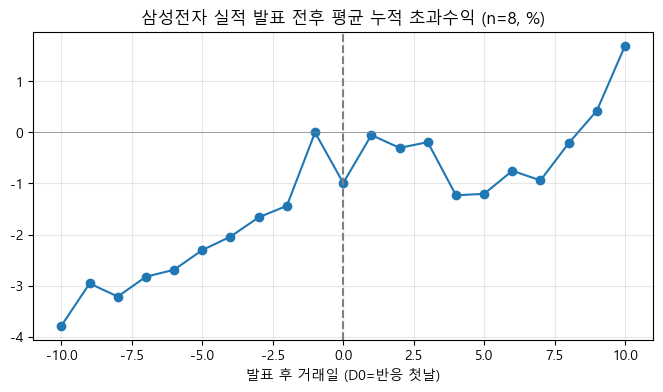

In [7]:
k = kospi.reindex(days).ffill()
ar = (px["close"].pct_change() - k.pct_change())
paths = {}
for _, a in ann.iterrows():
    p = d0_of(a["created_at"])
    if p is None or p - WINDOW < 1 or p + WINDOW >= len(days):
        continue
    seg = ar.iloc[p - WINDOW:p + WINDOW + 1].values
    paths[str(days[p].date())] = (pd.Series(seg).cumsum() - seg[:WINDOW].sum()) * 100  # D-1 종가 기준 0
car = pd.DataFrame(paths)
car.index = range(-WINDOW, WINDOW + 1)
ax = car.mean(axis=1).plot(figsize=(8, 4), marker="o", title=f"{NAME} 실적 발표 전후 평균 누적 초과수익 (n={car.shape[1]}, %)")
ax.axvline(0, color="gray", ls="--"); ax.axhline(0, color="gray", lw=.5); ax.set_xlabel("발표 후 거래일 (D0=반응 첫날)"); ax.grid(alpha=.3)

## 결과 읽는 법과 한계
- **발표 전 상승 + 발표 후 하락**이면 선반영(sell-the-news), **발표일 초과수익이 크면** 서프라이즈에 반응한 것입니다.
- 서프라이즈는 확정 분기 실적(재무제표) 기준입니다. 잠정 발표 수치와 조금 다를 수 있습니다.
- 컨센서스 표본은 DeepSearch가 받는 증권사(분기 추정은 대개 5~7곳)라 시장 전체 컨센서스보다 얇습니다.
- **외국인·기관 수급은 DeepSearch에 없어** 원본의 "누가 사고팔았나"는 재현할 수 없습니다.
- 공시 검색은 한 번에 1년까지라 그보다 긴 기간은 나눠서 찾아야 합니다.